Extracting EDF parameters from ../data/raw/S001R01.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 9759  =      0.000 ...    60.994 secs...
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 60 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 60.00 Hz
- Upper transition bandwidth: 15.00 Hz (-6 dB cutoff frequency: 67.50 Hz)
- Filter length: 529 samples (3.306 s)

Filtering raw data in 1 contiguous segment
Setting up band-stop filter from 49 - 51 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with

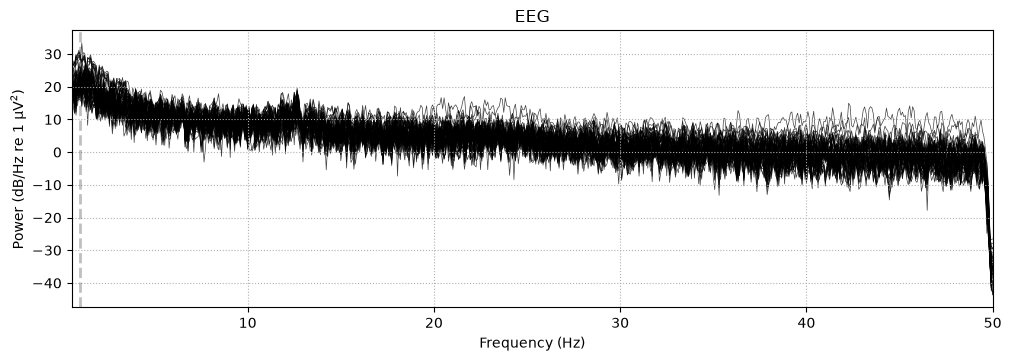

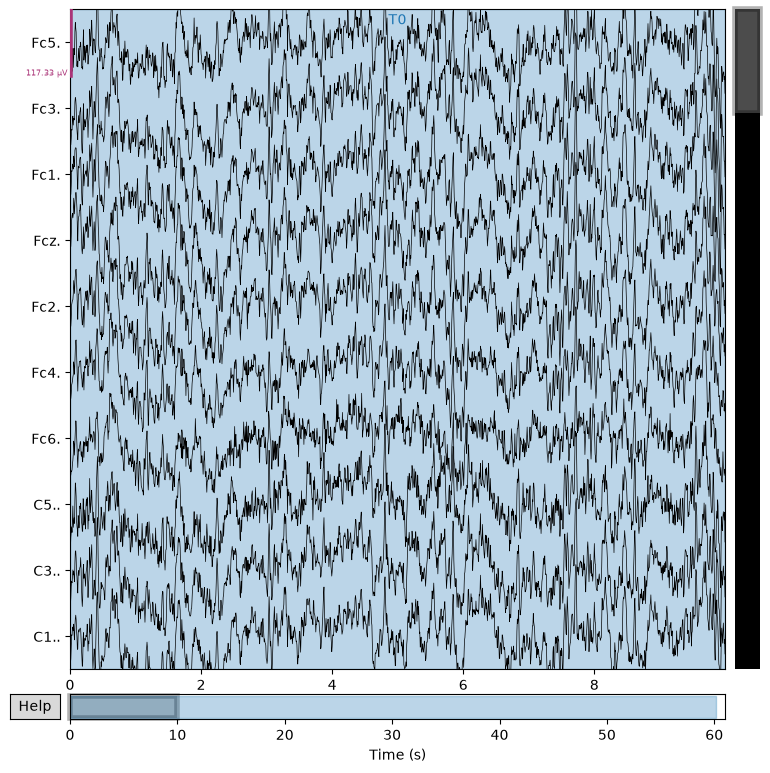

Effective window size : 12.800 (s)
Plotting power spectral density (dB=True).
Cleaned EEG:


C:\Users\mitta\AppData\Local\Temp\ipykernel_21888\3249063094.py:71: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  ).plot()
c:\Users\mitta\Desktop\SUB\Capstone\EEGRehab\.venv\Lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


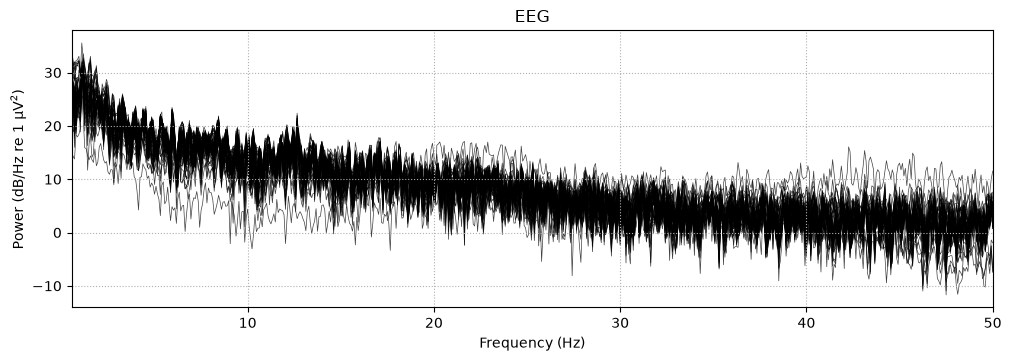

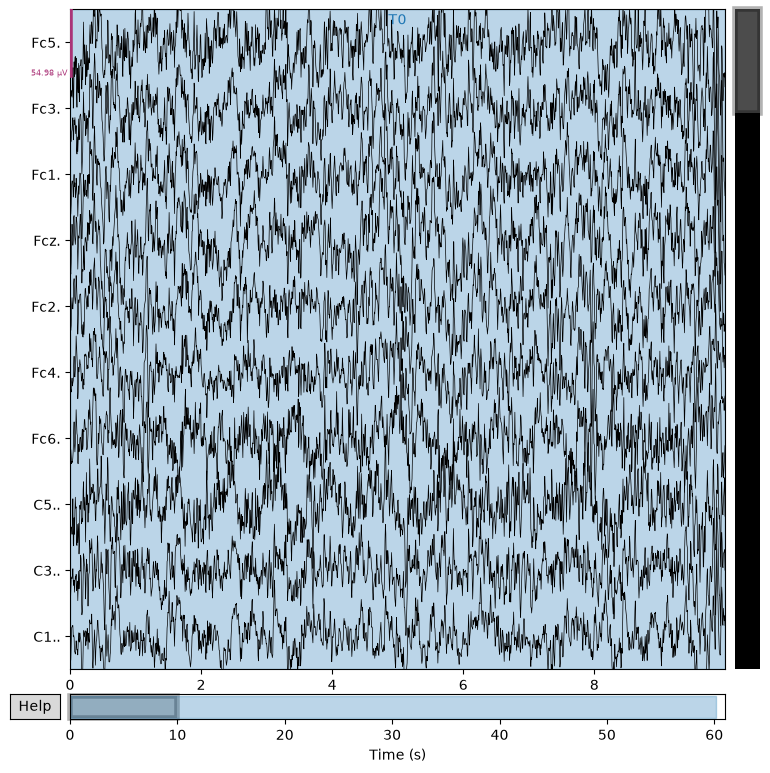

Effective window size : 12.800 (s)
Plotting power spectral density (dB=True).
===== EEG Quality Report =====
Number of epochs: 1
Number of channels: 64
Samples per epoch: 641
Data shape: (1, 64, 641)
NaN values: 0
Infinite values: 0
Minimum amplitude: -8.897703781285583e-05
Maximum amplitude: 9.913693725164196e-05
Mean amplitude: -4.2285576149980674e-23
Standard deviation: 1.8713129720684744e-05
Overwriting existing file.
Writing c:\Users\mitta\Desktop\SUB\Capstone\EEGRehab\notebooks\..\data\processed\S001R01\cleaned_raw.fif
Overwriting existing file.
Closing c:\Users\mitta\Desktop\SUB\Capstone\EEGRehab\notebooks\..\data\processed\S001R01\cleaned_raw.fif
[done]
Overwriting existing file.
Overwriting existing file.
Overwriting existing file.


C:\Users\mitta\AppData\Local\Temp\ipykernel_21888\3249063094.py:83: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  ).plot()
c:\Users\mitta\Desktop\SUB\Capstone\EEGRehab\.venv\Lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


NaN values: 0
Infinite values: 0
Feature matrix shape: (1, 1153)
   Fc5._mean  Fc5._std  Fc5._variance  Fc5._delta_power  Fc5._theta_power  \
0  -0.000002  0.000018   3.247904e-10      1.029358e-10      3.662584e-11   

   Fc5._alpha_power  Fc5._beta_power  Fc5._gamma_power  \
0      2.039541e-11     3.617674e-11      1.457711e-11   

   Fc5._delta_relative_power  Fc5._theta_relative_power  ...  \
0                   0.488517                    0.17382  ...   

   Iz.._theta_relative_power  Iz.._alpha_relative_power  \
0                   0.152893                   0.070788   

   Iz.._beta_relative_power  Iz.._gamma_relative_power  Iz.._peak_frequency  \
0                  0.189966                   0.064091                1.875   

   Iz.._hjorth_activity  Iz.._hjorth_mobility  Iz.._hjorth_complexity  \
0          6.609741e-10              0.562875                2.063096   

   Iz.._spectral_entropy  label  
0               4.945161      1  

[1 rows x 1153 columns]
['Fc5._mean', 'F

In [ ]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().parent))

from src.eeg_pipeline import run_eeg_pipeline
from src.validation.eeg_quality import validate_epochs
from src.storage.save_eeg import save_preprocessed_eeg
from src.features.extract_features import (
    extract_epoch_features
)

file_path = "../data/raw/S001R01.edf"

result = run_eeg_pipeline(file_path)

raw = result["raw"]
cleaned_raw = result["cleaned_raw"]
events = result["events"]
event_dict = result["event_dict"]
epochs = result["epochs"]

print(raw)
print(cleaned_raw)
print(events)
print(event_dict)
print(epochs)

print("Number of epochs:", len(epochs))
print("Number of channels:", len(epochs.ch_names))
print("Sampling frequency:", epochs.info["sfreq"])
print("Epoch shape:", epochs.get_data().shape)

print("Event dictionary:")
print(event_dict)

print("Epoch event IDs:")
print(epochs.event_id)

labels = epochs.events[:, 2]

event_ids = list(epochs.event_id.keys())
counts = [np.sum(epochs.events[:, 2] == event_id) for event_id in event_ids]

for event_id, count in zip(event_ids, counts):

    event_name = None

    for name, value in event_dict.items():
        if value == event_id:
            event_name = name
            break

    print(
        f"Event {event_id} ({event_name}): "
        f"{count} epochs"
    )

print("Raw EEG:")
raw.plot(
    duration=10,
    n_channels=10,
    scalings="auto"
)

raw.compute_psd(
    fmin=0.5,
    fmax=50
).plot()

print("Cleaned EEG:")
cleaned_raw.plot(
    duration=10,
    n_channels=10,
    scalings="auto"
)

cleaned_raw.compute_psd(
    fmin=0.5,
    fmax=50
).plot()

validate_epochs(epochs)

save_preprocessed_eeg(
    cleaned_raw,
    epochs,
    "../data/processed/S001R01"
)

feature_df = extract_epoch_features(
    epochs
)

print(
    "NaN values:",
    feature_df.isna().sum().sum()
)

print(
    "Infinite values:",
    np.isinf(
        feature_df.select_dtypes(
            include=np.number
        )
    ).sum().sum()
)

output_dir = Path(
    "../data/features"
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

feature_df.to_csv(
    output_dir / "S001R01_features.csv",
    index=False
)

print("Feature matrix shape:", feature_df.shape)
print(feature_df.head())
print(feature_df.columns.tolist())